## 0 SETUP

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

#### 1. Load Clean Data Set

In [61]:
df = pd.read_csv('hotel_bookings_clean.csv')
df.tail()

,hotel,is_canceled,lead_time,arrival_date_week_number,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,...,total_of_special_requests,has_agent,has_company,total_nights,total_guests,has_kids,arrival_month,arrival_weekday,adr_per_guest,has_prev_cancel
86632,City Hotel,0,23,35,2,5,2,0.0,0,BB,...,0,1,0,7,2.0,0,8,2,48.070000,0
86633,City Hotel,0,102,35,2,5,3,0.0,0,BB,...,2,1,0,7,3.0,0,8,3,75.143333,0
86634,City Hotel,0,34,35,2,5,2,0.0,0,BB,...,4,1,0,7,2.0,0,8,3,78.855000,0
86635,City Hotel,0,109,35,2,5,2,0.0,0,BB,...,0,1,0,7,2.0,0,8,3,52.200000,0
86636,City Hotel,0,205,35,2,7,2,0.0,0,HB,...,2,1,0,9,2.0,0,8,1,75.600000,0


#### 1.1 Check The dataset

In [62]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (86637, 34)

Column names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_agent', 'has_company', 'total_nights', 'total_guests', 'has_kids', 'arrival_month', 'arrival_weekday', 'adr_per_guest', 'has_prev_cancel']

Missing values in each column:
hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_week_number          0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                       

#### 1.2 Check the target variable

The is_canceled column is the answer the model will learn to predict:
- 0 = booking was not canceled
- 1 = booking was canceled

In [63]:
df["is_canceled"].value_counts()


is_canceled
0    62652
1    23985
Name: count, dtype: int64

#### 1.3 Check cancelation percentages

In [64]:
df["is_canceled"].value_counts(normalize=True).mul(100).round(2)

is_canceled
0    72.32
1    27.68
Name: proportion, dtype: float64

## 2 Pre-processing

In [65]:

# 1. Separate the target from the features

y = df["is_canceled"]

# 2. Remove columns that can reveal the final booking outcome
columns_to_remove = [
    "is_canceled",
    "reservation_status",
    "reservation_status_date"
]

X = df.drop(columns=columns_to_remove, errors="ignore")

# 3. Check the results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nLeakage check:")
print("reservation_status:", "reservation_status" in X.columns)
print("reservation_status_date:", "reservation_status_date" in X.columns)


Features shape: (86637, 33)
Target shape: (86637,)

Leakage check:
reservation_status: False
reservation_status_date: False


#### 2.1 Split the data into training and testing sets

We use 80% of the data for training and 20% for testing.

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 69309
Testing rows: 17328


#### 2.2 Identify numerical and categorical columns

Numerical columns contain numbers. Categorical columns contain labels or groups.

In [67]:
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical columns:")
print(num_cols)

print("\nCategorical columns:")
print(cat_cols)

Numerical columns:
['lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_agent', 'has_company', 'total_nights', 'total_guests', 'has_kids', 'arrival_month', 'arrival_weekday', 'adr_per_guest', 'has_prev_cancel']

Categorical columns:
['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']


#### 2.3— Create the preprocessing steps
- SimpleImputer fills missing values.
- StandardScaler standardizes numerical values.
- OneHotEncoder converts categories into numerical columns.
- ColumnTransformer applies the correct steps to each column group.

In [68]:
# Preprocessing for numerical columns
num_imputer = SimpleImputer(strategy="median")

# Preprocessing for categorical columns
cat_imputer = SimpleImputer(strategy="most_frequent")

encoder = OneHotEncoder(handle_unknown="ignore")

# Step 1: Fill missing numerical values
X_train_num = num_imputer.fit_transform(X_train[num_cols])
X_test_num = num_imputer.transform(X_test[num_cols])

# Step 2: Scale numerical values
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

# Step 3: Fill missing categorical values
X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

# Step 4: Encode categorical values
X_train_cat = encoder.fit_transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

print("Numerical training data:", X_train_num.shape)
print("Categorical training data:", X_train_cat.shape)

Numerical training data: (69309, 25)
Categorical training data: (69309, 203)


#### 2.4 - Combine the processed columns

In [69]:
from scipy.sparse import hstack, csr_matrix

# Convert numerical data into sparse format
X_train_num = csr_matrix(X_train_num)
X_test_num = csr_matrix(X_test_num)

# Combine numerical and categorical data
X_train_processed = hstack([X_train_num, X_train_cat]).tocsr()
X_test_processed = hstack([X_test_num, X_test_cat]).tocsr()

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (69309, 228)
Processed testing data: (17328, 228)


## 3. Classification Models - Five Classifiers
Logistic Regression

Decision Tree

Random Forest

Extra Trees

SGD Classifier

In [70]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "SGD Classifier": SGDClassifier(
        max_iter=1000,
        random_state=42
    )
}

#### 3.1 - Train the Five classifiers

In [71]:
fitted_models = {}

for name, clf in classifiers.items():

    # Train the model using the processed training data
    clf.fit(X_train_processed, y_train)

    # Save the trained model
    fitted_models[name] = clf

    print(name, "training completed")

Logistic Regression training completed
Decision Tree training completed
Random Forest training completed
Extra Trees training completed
SGD Classifier training completed


#### 3.2 - Compare model accuracy

In [72]:
from sklearn.metrics import accuracy_score

results = []

for name, model in fitted_models.items():

    # Predict cancellation using the test data
    predictions = model.predict(X_test_processed)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Model,Accuracy
1,Decision Tree,0.821791
0,Logistic Regression,0.790224
4,SGD Classifier,0.789070
2,Random Forest,0.765466
3,Extra Trees,0.745441


#### 3.3 -Visualize accuracy

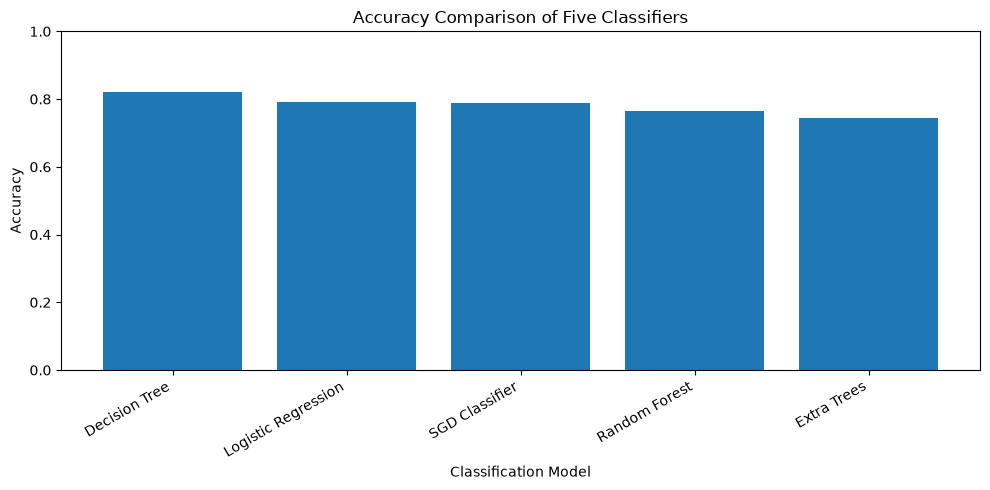

In [73]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Five Classifiers")
plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 4. - Confusion Matrix and Evaluation

A confusion matrix compares the actual outcomes with the model's predictions.
- True Negative (TN): correctly predicted a booking would not be canceled.
- False Positive (FP): predicted cancellation when the booking was not canceled.
- False Negative (FN): failed to identify a booking that was canceled.
- True Positive (TP): correctly predicted a cancellation.

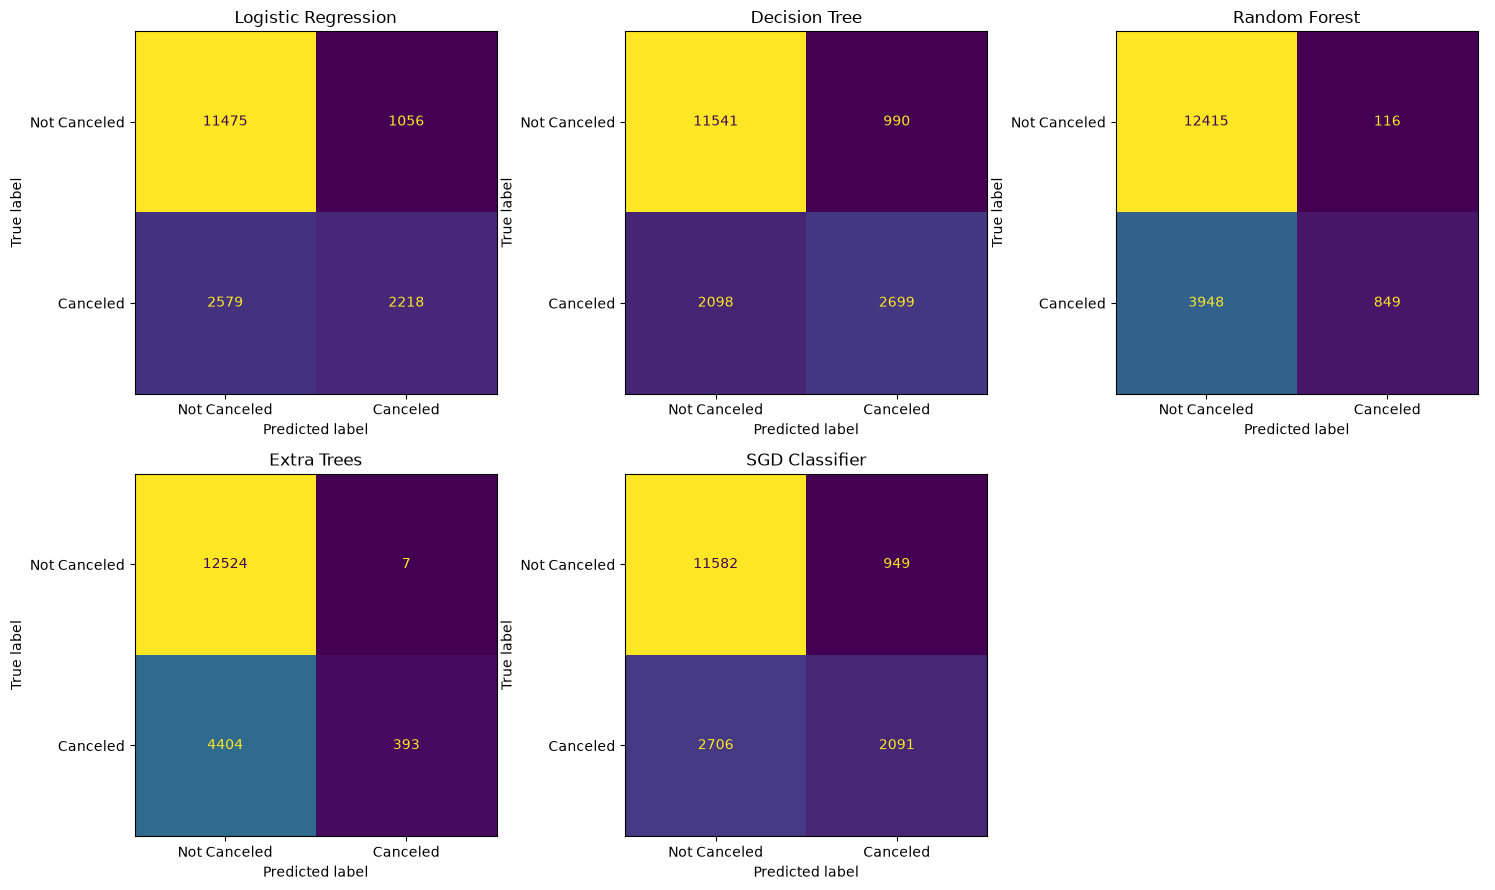

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, model) in enumerate(fitted_models.items()):

    # Predict using the test data
    predictions = model.predict(X_test_processed)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    # Display confusion matrix
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Canceled", "Canceled"]
    )

    display.plot(
        ax=axes[i],
        colorbar=False
    )

    axes[i].set_title(name)

# Hide the unused sixth plot
axes[5].axis("off")

plt.tight_layout()
plt.show()

#### 4.1 - Evaluate precision, recall, and F1-score
Accuracy alone is not enough. We also need to know how well each model identifies canceled bookings

In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

evaluation_results = []

for name, model in fitted_models.items():

    predictions = model.predict(X_test_processed)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    by="F1-Score",
    ascending=False
)

evaluation_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score
1,Decision Tree,0.822,0.732,0.563,0.636
0,Logistic Regression,0.790,0.677,0.462,0.550
4,SGD Classifier,0.789,0.688,0.436,0.534
2,Random Forest,0.765,0.880,0.177,0.295
3,Extra Trees,0.745,0.982,0.082,0.151


#### 4.2 View the detailed classification report

This example displays the report for the model with the highest F1-score in the comparison.

In [76]:
best_model_name = evaluation_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

best_predictions = best_model.predict(X_test_processed)

print("Model:", best_model_name)
print()

print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1],
        target_names=["Not Canceled", "Canceled"],
        zero_division=0
    )
)

Model: Decision Tree

              precision    recall  f1-score   support

Not Canceled       0.85      0.92      0.88     12531
    Canceled       0.73      0.56      0.64      4797

    accuracy                           0.82     17328
   macro avg       0.79      0.74      0.76     17328
weighted avg       0.81      0.82      0.81     17328



#### 4.3 - Display the confusion matrix counts for the selected model

In [77]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Selected model:", best_model_name)
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn, "<-- canceled bookings missed")
print("True Positives:", tp)

Selected model: Decision Tree
True Negatives: 11541
False Positives: 990
False Negatives: 2098 <-- canceled bookings missed
True Positives: 2699



#### 4.4 Analysis and Conclution

In [78]:
#. Final Analysis and Conclusion

from sklearn.metrics import confusion_matrix

print("=" * 60)
print("HOTEL BOOKING CANCELLATION - CLASSIFICATION CONCLUSION")
print("=" * 60)

# 1. Identify the model with the highest F1-score
best_row = evaluation_df.sort_values(
    by="F1-Score",
    ascending=False
).iloc[0]

best_model_name = best_row["Model"]
best_model = fitted_models[best_model_name]

print("\n1. BEST PERFORMING CLASSIFICATION MODEL")
print("-" * 60)

print(f"The model with the highest F1-score is {best_model_name}.")
print(f"Accuracy:  {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall:    {best_row['Recall']:.3f}")
print(f"F1-score:  {best_row['F1-Score']:.3f}")

# 2. Identify the model with the highest recall
recall_row = evaluation_df.sort_values(
    by="Recall",
    ascending=False
).iloc[0]

print("\n2. MODEL THAT IDENTIFIES CANCELLATIONS MOST EFFECTIVELY")
print("-" * 60)

print(f"The highest-recall model is {recall_row['Model']}.")
print(f"Its recall is {recall_row['Recall']:.3f}.")

print(
    "Recall measures the proportion of actual canceled bookings "
    "that the model correctly identifies."
)

# 3. Examine missed cancellations for the selected model
best_predictions = best_model.predict(X_test_processed)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("\n3. CANCELED BOOKINGS THAT THE MODEL MISSED")
print("-" * 60)

print(f"Correctly predicted non-canceled bookings: {tn}")
print(f"Non-canceled bookings incorrectly flagged: {fp}")
print(f"Canceled bookings missed by the model:     {fn}")
print(f"Correctly predicted canceled bookings:      {tp}")

if fn == 0:
    print("The model did not miss any canceled bookings in this test set.")
else:
    print(
        f"The model missed {fn} canceled bookings in the test set. "
        "These cases may represent opportunities for improving "
        "cancellation prediction."
    )

# 4. Explain how prediction could help hotels
print("\n4. HOW CANCELLATION PREDICTION CAN HELP HOTELS")
print("-" * 60)

print(
    "A cancellation prediction model can help hotels identify "
    "bookings that may be at risk of cancellation. Hotel staff could "
    "use these predictions to plan room availability, communicate "
    "with guests, and develop suitable booking or deposit policies. "
    "Predictions should support decisions rather than automatically "
    "determine how guests are treated."
)

# 5. Explain the limitations
print("\n5. LIMITATIONS OF THIS ANALYSIS")
print("-" * 60)

print(
    "This comparison uses one training and testing split. The results "
    "may change with a different split or dataset. The highest F1-score "
    "does not automatically mean a model is best for every hotel."
)

print(
    "The model may also be affected by missing data, class imbalance, "
    "and the features available when a booking is first made. Before "
    "using a model in practice, it should be evaluated with "
    "cross-validation and tested on data that reflects real future "
    "bookings. Model selection should be completed using training data "
    "before the final test set is used for evaluation."
)

print("\n" + "=" * 60)
print("END OF CLASSIFICATION ANALYSIS")
print("=" * 60)

HOTEL BOOKING CANCELLATION - CLASSIFICATION CONCLUSION

1. BEST PERFORMING CLASSIFICATION MODEL
------------------------------------------------------------
The model with the highest F1-score is Decision Tree.
Accuracy:  0.822
Precision: 0.732
Recall:    0.563
F1-score:  0.636

2. MODEL THAT IDENTIFIES CANCELLATIONS MOST EFFECTIVELY
------------------------------------------------------------
The highest-recall model is Decision Tree.
Its recall is 0.563.
Recall measures the proportion of actual canceled bookings that the model correctly identifies.

3. CANCELED BOOKINGS THAT THE MODEL MISSED
------------------------------------------------------------
Correctly predicted non-canceled bookings: 11541
Non-canceled bookings incorrectly flagged: 990
Canceled bookings missed by the model:     2098
Correctly predicted canceled bookings:      2699
The model missed 2098 canceled bookings in the test set. These cases may represent opportunities for improving cancellation prediction.

4. HOW C